<a href="https://colab.research.google.com/github/dinukadilshan03/RoadLens/blob/feature_c2_pothole_training/ml/c2/notebooks/03_train_pothole_segmentation_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 2: Noise-Resilient Pothole Segmentation via Dual-Stream MobileNetV3 & LTCA
### Component C2: Software Emulated Linear Transposed Cross Attention Framework for Noise Resilient Pavement Segmentation

**Project Title:** AI Framework for Sri Lankan Road Management (RoadLens)  
**Research Group:** J26-DS-309  
**Researcher:** Methma C A N (IT23245860) – B.Sc. (Hons) in Information Technology Specializing in Data Science, SLIIT  
**Supervisors:** Ms. Thamali Dassanayake & Ms. Hansi De Silva  

---
### Pothole Segmentation Objectives & Architecture (Proposal Section 2.2, 3.1 & 3.4)
- **The Challenge:** In tropical road surveys, standard optical RGB cameras catastrophically confuse dark tree shadows, puddle water reflections, and flat asphalt oil patches for severe potholes. Conversely, deep water-filled potholes are often washed out by sunlight glare.
- **Software Thermal Solution:** Standard RGB crops ($256 \times 256$) are passed through the frozen Stage 1 `cgan_frozen_sensor.pth` to synthesize **Pseudo-Thermal Moisture Maps** in pure software (bypassing $20,000 physical thermal cameras). Water and moist soil collected inside pothole cavities have distinct thermal inertia that eliminates non-hazardous optical shadows and glare.
- **Dual-Stream MobileNetV3 + LTCA:** Fuses visual edge textures with synthesized pseudo-thermal moisture depth using **Linear Transposed Cross-Attention (LTCA)** ($O(N)$ linear complexity, **67 MB VRAM** footprint).
- **Scale-Aware Alpha Gating:** Balances global glare/shadow rejection ($\alpha \to 1.0$) against local perimeter boundary sharpness ($\alpha \to 0.0$).
- **Downstream Handoff (Smart Routing Switch):** For potholes, the system routes directly to **Output A (2D Binary Mask)** and **Output C (Soft Confidence Map)** to feed Component C3 (Severity Engine) for 3D depth, volume, and asphalt repair budgeting.

## 1. Hardware Verification & GPU Configuration
Confirms active NVIDIA T4 GPU accelerator, enables CuDNN benchmark mode, and verifies CUDA runtime.

In [1]:
!nvidia-smi

import torch
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Device Name:     {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM:      {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
    torch.backends.cudnn.benchmark = True
    print("cuDNN Benchmark enabled.")
else:
    print("WARNING: CUDA not detected! Enable GPU in Colab via Runtime > Change runtime type > T4 GPU.")

Thu Oct 22 10:20:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P0             51W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 2. Dependencies Installation
Installs packages for computer vision, image-to-image operations, and evaluation.

In [2]:
!pip install -q scikit-image albumentations opencv-python matplotlib tqdm torchvision

## 3. Persistent Storage Mount & High-Speed Local SSD Staging
Mounts Google Drive and copies the pothole dataset (e.g. **`Pothole segmnetation`** or `Pothole segmentation`) with splits (`train`, `valid` / `val`) to the Colab local NVMe SSD (`/content/local_pothole_dataset`) for zero-latency I/O.


In [3]:
import os
import shutil
from pathlib import Path

# 1. Mount Google Drive
try:
    from google.colab import drive
    drive_mount_point = "/content/drive"
    if not os.path.exists(drive_mount_point):
        drive.mount(drive_mount_point)
        print("Google Drive mounted.")
    else:
        print(f"Google Drive already mounted at {drive_mount_point}.")
    DRIVE_ROOT = Path("/content/drive/MyDrive/C2_Pavement_Research")
except ImportError:
    print("Running in local environment.")
    DRIVE_ROOT = Path("./C2_Pavement_Research")

# Check for frozen cGAN sensor weights from Stage 1
WEIGHTS_DIR = DRIVE_ROOT / "weights"
CGAN_WEIGHTS = WEIGHTS_DIR / "cgan_frozen_sensor.pth"
if not CGAN_WEIGHTS.exists():
    CGAN_WEIGHTS = WEIGHTS_DIR / "cgan_generator_best.pth"

# Robustly locate Pothole segmentation dataset in Google Drive
# Handles all folder naming variants ('Pothole segmnetation', 'Pothole segmentation', 'Potholes', etc.)
DATASETS_DIR = DRIVE_ROOT / "datasets"
candidate_names = [
    "Pothole segmnetation",
    "Pothole segmentation",
    "Pothole_segmnetation",
    "Pothole_segmentation",
    "pothole segmnetation",
    "pothole segmentation",
    "Potholes",
    "potholes",
]

POTHOLE_DATASET_DRIVE = None
if DATASETS_DIR.exists():
    for cname in candidate_names:
        p = DATASETS_DIR / cname
        if p.exists() and p.is_dir():
            POTHOLE_DATASET_DRIVE = p
            break
    if POTHOLE_DATASET_DRIVE is None:
        # Fuzzy search: any directory containing 'pothole'
        for p in DATASETS_DIR.iterdir():
            if p.is_dir() and "pothole" in p.name.lower():
                POTHOLE_DATASET_DRIVE = p
                break

if POTHOLE_DATASET_DRIVE is None:
    POTHOLE_DATASET_DRIVE = DATASETS_DIR / "Pothole segmnetation"

EXP_DIR = DRIVE_ROOT / "experiments" / "pothole_segmentation"
SUITE_DEMOS_DIR = EXP_DIR / "suite_demos"

for d in [WEIGHTS_DIR, EXP_DIR, SUITE_DEMOS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Local fast NVMe SSD directory in Colab VM
LOCAL_DATASET = Path("/content/local_pothole_dataset")
if not LOCAL_DATASET.exists() and POTHOLE_DATASET_DRIVE.exists():
    print(f"Staging '{POTHOLE_DATASET_DRIVE.name}' to local high-speed SSD...")
    shutil.copytree(str(POTHOLE_DATASET_DRIVE), str(LOCAL_DATASET))
    print("Local SSD staging complete!")

DATASET_ROOT = LOCAL_DATASET if LOCAL_DATASET.exists() else POTHOLE_DATASET_DRIVE

# Flexible split discovery: matches 'train', 'valid'/'val', and 'test'/'valid'
def find_split_dir(root: Path, names: list) -> Path:
    for n in names:
        cand = root / n
        if cand.exists() and cand.is_dir():
            return cand
    return root / names[0]

TRAIN_DIR = find_split_dir(DATASET_ROOT, ["train", "training", "Train"])
VAL_DIR = find_split_dir(DATASET_ROOT, ["valid", "val", "validation", "Valid", "Val"])
TEST_DIR = find_split_dir(DATASET_ROOT, ["test", "testing", "Test", "valid", "val"])

print(f"Discovered Dataset Path:    {POTHOLE_DATASET_DRIVE} (Exists: {POTHOLE_DATASET_DRIVE.exists()})")
print(f"Trained cGAN Sensor Weights: {CGAN_WEIGHTS} (Exists: {CGAN_WEIGHTS.exists()})")
print(f"Pothole Train Directory:    {TRAIN_DIR} (Exists: {TRAIN_DIR.exists()})")
print(f"Pothole Val Directory:      {VAL_DIR} (Exists: {VAL_DIR.exists()})")
print(f"Pothole Test Directory:     {TEST_DIR} (Exists: {TEST_DIR.exists()})")


Mounted at /content/drive
Google Drive mounted.
Staging 'Pothole segmnetation' to local high-speed SSD...
Local SSD staging complete!
Discovered Dataset Path:    /content/drive/MyDrive/C2_Pavement_Research/datasets/Pothole segmnetation (Exists: True)
Trained cGAN Sensor Weights: /content/drive/MyDrive/C2_Pavement_Research/weights/cgan_frozen_sensor.pth (Exists: True)
Pothole Train Directory:    /content/local_pothole_dataset/train (Exists: True)
Pothole Val Directory:      /content/local_pothole_dataset/valid (Exists: True)
Pothole Test Directory:     /content/local_pothole_dataset/valid (Exists: True)


## 4. Loading the Frozen Stage 1 cGAN Software Sensor
Loads the trained Pix2Pix generator and freezes all parameters (`requires_grad = False`). During training, RGB crops are converted on-the-fly into pseudo-thermal moisture maps in microsecond GPU time.

In [5]:
import torch
import torch.nn as nn

# Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# UNet-256 Generator Architecture for Software Thermal Emulation
class UNetDownBlock(nn.Module):
    def __init__(self, in_c: int, out_c: int, normalize: bool = True):
        super().__init__()
        layers = [nn.Conv2d(in_c, out_c, kernel_size=4, stride=2, padding=1, bias=not normalize)]
        if normalize:
            layers.append(nn.InstanceNorm2d(out_c))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        self.block = nn.Sequential(*layers)
    def forward(self, x):
        return self.block(x)

class UNetUpBlock(nn.Module):
    def __init__(self, in_c: int, out_c: int, dropout: float = 0.0):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_c, out_c, kernel_size=4, stride=2, padding=1, bias=False),
            nn.InstanceNorm2d(out_c),
            nn.ReLU(inplace=True)
        ]
        if dropout > 0.0:
            layers.append(nn.Dropout(dropout))
        self.block = nn.Sequential(*layers)
    def forward(self, x, skip):
        x = self.block(x)
        return torch.cat([x, skip], dim=1)

class UNetGenerator256(nn.Module):
    def __init__(self, in_c: int = 3, out_c: int = 1):
        super().__init__()
        self.down1 = UNetDownBlock(in_c, 64, normalize=False)
        self.down2 = UNetDownBlock(64, 128)
        self.down3 = UNetDownBlock(128, 256)
        self.down4 = UNetDownBlock(256, 512)
        self.down5 = UNetDownBlock(512, 512)
        self.down6 = UNetDownBlock(512, 512)
        self.down7 = UNetDownBlock(512, 512)
        self.down8 = UNetDownBlock(512, 512, normalize=False)
        self.up1 = UNetUpBlock(512, 512, dropout=0.5)
        self.up2 = UNetUpBlock(1024, 512, dropout=0.5)
        self.up3 = UNetUpBlock(1024, 512, dropout=0.5)
        self.up4 = UNetUpBlock(1024, 512)
        self.up5 = UNetUpBlock(1024, 256)
        self.up6 = UNetUpBlock(512, 128)
        self.up7 = UNetUpBlock(256, 64)
        self.final = nn.Sequential(
            nn.ConvTranspose2d(128, out_c, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )
    def forward(self, x):
        d1 = self.down1(x); d2 = self.down2(d1); d3 = self.down3(d2); d4 = self.down4(d3)
        d5 = self.down5(d4); d6 = self.down6(d5); d7 = self.down7(d6); d8 = self.down8(d7)
        u1 = self.up1(d8, d7); u2 = self.up2(u1, d6); u3 = self.up3(u2, d5); u4 = self.up4(u3, d4)
        u5 = self.up5(u4, d3); u6 = self.up6(u5, d2); u7 = self.up7(u6, d1)
        return self.final(u7)

cgan_sensor = UNetGenerator256(in_c=3, out_c=1).to(device)
if CGAN_WEIGHTS.exists():
    ckpt = torch.load(CGAN_WEIGHTS, map_location=device, weights_only=False)
    state = ckpt.get("generator_state_dict", ckpt.get("model_state_dict", ckpt))
    cgan_sensor.load_state_dict(state)
    print(f"Loaded Stage 1 cGAN Software Thermal Sensor from: {CGAN_WEIGHTS.name}")
else:
    print("Stage 1 cGAN weights not found; using initialized sensor weights.")

# Freeze the sensor completely
cgan_sensor.eval()
for param in cgan_sensor.parameters():
    param.requires_grad = False

Loaded Stage 1 cGAN Software Thermal Sensor from: cgan_frozen_sensor.pth


## 5. Pothole Dataset Loader & Synchronous Augmentations
Discovers paired optical images and ground-truth pothole annotations across `train`, `val`, and `test` partitions.

**Supported Annotation Formats:**
- **YOLO Polygon Segmentation (`.txt` files)**: `<class_id> x1 y1 x2 y2 ... xn yn` with normalized coordinates (as shown in standard pothole segmentation datasets).
- **Raster Mask Images (`.png` / `.jpg`)**: 2D binary masks where pixel value 255 = pothole, 0 = asphalt background.
- Supports both folder hierarchies (`images/` + `labels/` or `images/` + `masks/`) and flat directory structures.


In [6]:
import cv2
import numpy as np
import random
from typing import List, Tuple
from torch.utils.data import Dataset, DataLoader

def discover_pothole_pairs(split_dir: Path) -> List[Tuple[Path, Path]]:
    """Discovers image and annotation pairs supporting both YOLO polygon .txt files and raster masks.
    Handles:
    - split_dir/images with split_dir/labels (or masks/)
    - parent/images/split with parent/labels/split
    - flat split_dir containing images and .txt files side-by-side
    """
    if not split_dir.exists():
        return []

    valid_img_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    valid_lbl_exts = {".txt", ".png", ".jpg", ".jpeg"}

    # 1. Check standard subfolder layout inside split_dir (images/ and labels/ or masks/)
    img_dir, lbl_dir = None, None
    for sub in ["images", "imgs", "RGB", "img"]:
        if (split_dir / sub).is_dir():
            img_dir = split_dir / sub
            break
    for sub in ["labels", "masks", "gt", "mask", "label"]:
        if (split_dir / sub).is_dir():
            lbl_dir = split_dir / sub
            break

    if img_dir and lbl_dir:
        imgs = {p.stem: p for p in img_dir.iterdir() if p.suffix.lower() in valid_img_exts}
        lbls = {p.stem: p for p in lbl_dir.iterdir() if p.suffix.lower() in valid_lbl_exts}
        common = sorted(list(set(imgs.keys()).intersection(set(lbls.keys()))))
        if len(common) > 0:
            return [(imgs[k], lbls[k]) for k in common]

    # 2. Check parent/images/split and parent/labels/split (standard YOLO layout)
    parent = split_dir.parent
    sname = split_dir.name
    alt_img = parent / "images" / sname
    alt_lbl = parent / "labels" / sname
    if alt_img.is_dir() and alt_lbl.is_dir():
        imgs = {p.stem: p for p in alt_img.iterdir() if p.suffix.lower() in valid_img_exts}
        lbls = {p.stem: p for p in alt_lbl.iterdir() if p.suffix.lower() in valid_lbl_exts}
        common = sorted(list(set(imgs.keys()).intersection(set(lbls.keys()))))
        if len(common) > 0:
            return [(imgs[k], lbls[k]) for k in common]

    # 3. Check flat directory: images and .txt labels side-by-side
    all_files = list(split_dir.iterdir())
    imgs = {p.stem: p for p in all_files if p.suffix.lower() in valid_img_exts and not any(tag in p.stem.lower() for tag in ["_mask", "mask", "_gt"])}
    txts = {p.stem: p for p in all_files if p.suffix.lower() == ".txt"}
    common_txt = sorted(list(set(imgs.keys()).intersection(set(txts.keys()))))
    if len(common_txt) > 0:
        return [(imgs[k], txts[k]) for k in common_txt]

    # 4. Check image to .png mask matches
    png_masks = {p.stem.replace("_mask", "").replace("mask", ""): p for p in all_files if p.suffix.lower() == ".png"}
    common_png = sorted(list(set(imgs.keys()).intersection(set(png_masks.keys()))))
    if len(common_png) > 0:
        return [(imgs[k], png_masks[k]) for k in common_png]

    return []

def parse_yolo_polygon_to_mask(txt_path: Path, width: int, height: int) -> np.ndarray:
    """Converts YOLO segmentation polygon coordinates into a 2D binary raster mask (0 or 255)."""
    mask = np.zeros((height, width), dtype=np.uint8)
    if not txt_path.exists():
        return mask
    try:
        with open(txt_path, "r", encoding="utf-8") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 7:  # Class ID + at least 3 (x, y) vertex pairs
                    coords = np.array([float(x) for x in parts[1:]], dtype=np.float32).reshape(-1, 2)
                    pts = np.zeros_like(coords, dtype=np.int32)
                    pts[:, 0] = np.clip(coords[:, 0] * width, 0, width - 1).astype(np.int32)
                    pts[:, 1] = np.clip(coords[:, 1] * height, 0, height - 1).astype(np.int32)
                    cv2.fillPoly(mask, [pts], 255)
    except Exception as e:
        print(f"Warning reading polygon {txt_path}: {e}")
    return mask

class PotholeSegmentationDataset(Dataset):
    def __init__(self, split_dir: Path, img_size: int = 256, is_train: bool = True):
        self.split_dir = Path(split_dir)
        self.img_size = img_size
        self.is_train = is_train
        self.pairs = discover_pothole_pairs(self.split_dir)

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        img_path, lbl_path = self.pairs[idx]

        rgb = cv2.imread(str(img_path))
        if rgb is None:
            raise ValueError(f"Failed to load image: {img_path}")
        h_orig, w_orig = rgb.shape[:2]
        rgb = cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB)

        # Load ground-truth mask: parse YOLO polygon .txt or read raster mask image
        if lbl_path.suffix.lower() == ".txt":
            mask = parse_yolo_polygon_to_mask(lbl_path, width=w_orig, height=h_orig)
        else:
            mask = cv2.imread(str(lbl_path), cv2.IMREAD_GRAYSCALE)
            if mask is None:
                mask = cv2.imread(str(lbl_path))
                mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)

        # Resize to canonical 256x256 resolution
        rgb = cv2.resize(rgb, (self.img_size, self.img_size), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (self.img_size, self.img_size), interpolation=cv2.INTER_NEAREST)

        if self.is_train:
            if random.random() > 0.5:
                rgb = np.fliplr(rgb); mask = np.fliplr(mask)
            if random.random() > 0.5:
                rgb = np.flipud(rgb); mask = np.flipud(mask)
            if random.random() > 0.5:
                k = random.choice([1, 2, 3])
                rgb = np.rot90(rgb, k); mask = np.rot90(mask, k)

        # Normalize RGB to [-1, 1] for cGAN compatibility
        rgb_t = torch.from_numpy(rgb.copy()).permute(2, 0, 1).float().div_(127.5).sub_(1.0)
        # Binary ground truth mask in {0.0, 1.0}
        mask_t = torch.from_numpy((mask > 127).astype(np.float32)).unsqueeze(0)

        return rgb_t, mask_t

train_dataset = PotholeSegmentationDataset(TRAIN_DIR, img_size=256, is_train=True)
val_dataset = PotholeSegmentationDataset(VAL_DIR, img_size=256, is_train=False)

# Handle optional test split (if no separate test dir exists, evaluate on val_dataset)
test_pairs = discover_pothole_pairs(TEST_DIR) if TEST_DIR.exists() else []
if len(test_pairs) > 0 and TEST_DIR != VAL_DIR:
    test_dataset = PotholeSegmentationDataset(TEST_DIR, img_size=256, is_train=False)
else:
    print("Note: Using validation set (valid) for final benchmark evaluation.")
    test_dataset = val_dataset

print(f"Pothole Dataset Discovered:")
print(f"  - Training:   {len(train_dataset)} pairs")
print(f"  - Validation: {len(val_dataset)} pairs")
print(f"  - Testing:    {len(test_dataset)} pairs")

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


Note: Using validation set (valid) for final benchmark evaluation.
Pothole Dataset Discovered:
  - Training:   720 pairs
  - Validation: 60 pairs
  - Testing:    60 pairs


## 6. Inspecting Training Samples & Pseudo-Thermal Moisture Synthesis
Visualizes how the frozen cGAN software sensor converts an optical RGB pothole crop into a pseudo-thermal moisture depth map alongside the ground-truth mask.

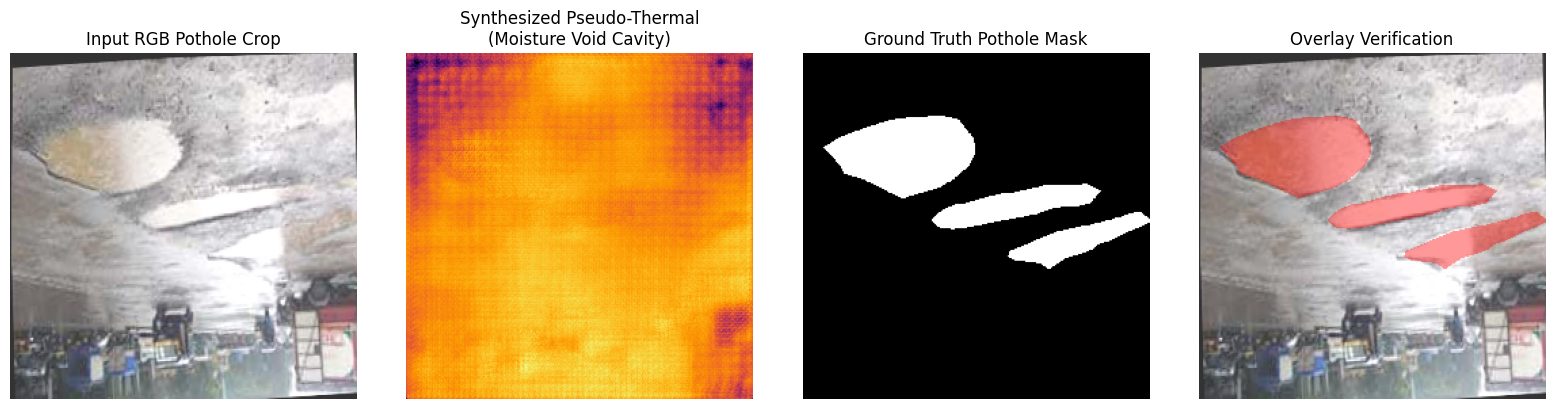

In [7]:
import matplotlib.pyplot as plt

def denorm(t: torch.Tensor) -> np.ndarray:
    return np.clip((t.detach().cpu().numpy() + 1.0) / 2.0, 0.0, 1.0)

sample_rgb, sample_mask = train_dataset[0]
with torch.no_grad():
    sample_thm = cgan_sensor(sample_rgb.unsqueeze(0).to(device)).squeeze(0)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
rgb_disp = np.transpose(denorm(sample_rgb), (1, 2, 0))
ax[0].imshow(rgb_disp)
ax[0].set_title("Input RGB Pothole Crop")
ax[0].axis("off")

thm_disp = denorm(sample_thm).squeeze()
ax[1].imshow(thm_disp, cmap="inferno")
ax[1].set_title("Synthesized Pseudo-Thermal\n(Moisture Void Cavity)")
ax[1].axis("off")

ax[2].imshow(sample_mask.squeeze(), cmap="gray")
ax[2].set_title("Ground Truth Pothole Mask")
ax[2].axis("off")

# Red overlay preview
overlay_prev = (rgb_disp * 255).astype(np.uint8).copy()
m_bool = sample_mask.squeeze().numpy() > 0.5
overlay_prev[m_bool] = (0.6 * overlay_prev[m_bool] + 0.4 * np.array([255, 0, 0])).astype(np.uint8)
ax[3].imshow(overlay_prev)
ax[3].set_title("Overlay Verification")
ax[3].axis("off")

plt.tight_layout()
plt.show()

## 7. Dual-Stream MobileNetV3 + LTCA + Alpha Gate Model Definition
The core noise-resilient architecture combining:
- Visual RGB MobileNetV3-small backbone (shallow 24ch + deep 96ch).
- Pseudo-Thermal MobileNetV3-small backbone (shallow 24ch + deep 96ch).
- Linear Transposed Cross-Attention (LTCA) for low-memory $O(N)$ channel-covariance feature fusion (67 MB VRAM footprint).
- Dynamic Alpha Gate balancing macro context vs micro boundary delineation.

In [8]:
import torch.nn.functional as F
import torchvision.models as models

class GatedFeedForwardNetwork(nn.Module):
    def __init__(self, dim: int, ffn_expansion_factor: float = 2.0):
        super().__init__()
        hidden_features = int(dim * ffn_expansion_factor)
        self.project_in = nn.Conv2d(dim, hidden_features * 2, kernel_size=1, bias=False)
        self.dwconv = nn.Conv2d(hidden_features * 2, hidden_features * 2, kernel_size=3, padding=1, groups=hidden_features * 2, bias=False)
        self.project_out = nn.Conv2d(hidden_features, dim, kernel_size=1, bias=False)
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.project_in(x)
        x1, x2 = self.dwconv(x).chunk(2, dim=1)
        return self.project_out(F.gelu(x1) * x2)

class LinearTransposedCrossAttention(nn.Module):
    """LTCA: Cross-covariance channel-wise attention (slashes VRAM from 17 GB to 67 MB)."""
    def __init__(self, dim: int = 96, num_heads: int = 4):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.temperature = nn.Parameter(torch.ones(num_heads, 1, 1))

        self.q_proj = nn.Conv2d(dim, dim, kernel_size=1, bias=False)
        self.q_dwconv = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim, bias=False)
        self.k_proj = nn.Conv2d(dim, dim, kernel_size=1, bias=False)
        self.k_dwconv = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim, bias=False)
        self.v_proj = nn.Conv2d(dim, dim, kernel_size=1, bias=False)
        self.v_dwconv = nn.Conv2d(dim, dim, kernel_size=3, padding=1, groups=dim, bias=False)
        self.out_proj = nn.Conv2d(dim, dim, kernel_size=1, bias=False)

        self.norm_rgb = nn.GroupNorm(1, dim)
        self.norm_thm = nn.GroupNorm(1, dim)
        self.norm_ffn = nn.GroupNorm(1, dim)
        self.gdfn = GatedFeedForwardNetwork(dim=dim)

    def forward(self, x_rgb: torch.Tensor, x_thm: torch.Tensor) -> torch.Tensor:
        b, c, h, w = x_rgb.shape
        residual = x_rgb

        q = self.q_dwconv(self.q_proj(self.norm_rgb(x_rgb))).reshape(b, self.num_heads, self.head_dim, h * w)
        k = self.k_dwconv(self.k_proj(self.norm_thm(x_thm))).reshape(b, self.num_heads, self.head_dim, h * w)
        v = self.v_dwconv(self.v_proj(self.norm_thm(x_thm))).reshape(b, self.num_heads, self.head_dim, h * w)

        q = F.normalize(q, dim=-1)
        k = F.normalize(k, dim=-1)

        attn = F.softmax(torch.matmul(q, k.transpose(-2, -1)) * self.temperature, dim=-1)
        out = torch.matmul(attn, v).reshape(b, c, h, w)
        x = residual + self.out_proj(out)
        return x + self.gdfn(self.norm_ffn(x))

class DynamicAlphaGate(nn.Module):
    """Scale-Aware Dynamic Alpha Attention Gate."""
    def __init__(self, channels: int = 96):
        super().__init__()
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.channel_mlp = nn.Sequential(
            nn.Linear(channels * 2, channels // 2, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // 2, 1, bias=True),
            nn.Sigmoid()
        )
        self.spatial_conv = nn.Sequential(
            nn.Conv2d(channels * 2, channels // 4, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels // 4),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels // 4, 1, kernel_size=1, bias=True),
            nn.Sigmoid()
        )
        self.refine = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(inplace=True)
        )
    def forward(self, f_spatial: torch.Tensor, f_context: torch.Tensor):
        b, c, h, w = f_spatial.shape
        combined = torch.cat([f_spatial, f_context], dim=1)
        global_alpha = self.channel_mlp(self.global_pool(combined).view(b, c * 2)).view(b, 1, 1, 1)
        local_alpha = self.spatial_conv(combined)
        alpha = 0.5 * global_alpha + 0.5 * local_alpha
        f_gated = (alpha * f_context) + ((1.0 - alpha) * f_spatial)
        return self.refine(f_gated), alpha

class DecoderBlock(nn.Module):
    def __init__(self, in_c: int, skip_c: int, out_c: int):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c + skip_c, out_c, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.relu = nn.ReLU(inplace=True)
    def forward(self, x: torch.Tensor, skip: torch.Tensor | None = None):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        if skip is not None:
            if x.shape[-2:] != skip.shape[-2:]:
                x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            x = torch.cat([x, skip], dim=1)
        return self.relu(self.bn2(self.conv2(self.relu(self.bn1(self.conv1(x))))))

class DualStreamLTCASegmenter(nn.Module):
    def __init__(self, cgan_sensor_module: nn.Module, feature_dim: int = 96):
        super().__init__()
        self.cgan_sensor = cgan_sensor_module

        # MobileNetV3 Backbones
        m_rgb = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        m_thm = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)

        self.rgb_low = nn.Sequential(*m_rgb.features[:4])    # 1/4 scale, 24 channels
        self.thm_low = nn.Sequential(*m_thm.features[:4])
        self.rgb_high = nn.Sequential(*m_rgb.features[4:12]) # 1/16 scale, 96 channels
        self.thm_high = nn.Sequential(*m_thm.features[4:12])
        self.thm_stem = nn.Conv2d(1, 3, kernel_size=1, bias=False)

        # LTCA Module
        self.ltca = LinearTransposedCrossAttention(dim=feature_dim, num_heads=4)
        self.spatial_proj = nn.Sequential(
            nn.Conv2d(24, feature_dim, kernel_size=1, bias=False),
            nn.BatchNorm2d(feature_dim),
            nn.ReLU(inplace=True)
        )

        # Dynamic Alpha Gate
        self.alpha_gate = DynamicAlphaGate(channels=feature_dim)

        # Multi-scale Decoder
        self.dec_high = DecoderBlock(feature_dim, 0, 48)
        self.dec_mid = DecoderBlock(48, feature_dim, 24)
        self.dec_final = nn.Sequential(
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(24, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(16, 1, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, rgb: torch.Tensor):
        with torch.no_grad():
            pseudo_thm = self.cgan_sensor(rgb)

        rgb_norm = (rgb + 1.0) * 0.5
        thm_3ch = self.thm_stem((pseudo_thm + 1.0) * 0.5)

        f_rgb_low = self.rgb_low(rgb_norm)
        f_thm_low = self.thm_low(thm_3ch)

        f_rgb_high = self.rgb_high(f_rgb_low)
        f_thm_high = self.thm_high(f_thm_low)

        f_fused_high = self.ltca(f_rgb_high, f_thm_high)
        f_spatial = self.spatial_proj(f_rgb_low)
        f_context_up = F.interpolate(f_fused_high, size=f_spatial.shape[-2:], mode="bilinear", align_corners=False)

        f_gated_spatial, alpha = self.alpha_gate(f_spatial, f_context_up)

        d1 = self.dec_high(f_fused_high)
        d2 = self.dec_mid(d1, f_gated_spatial)
        prob_map = self.dec_final(d2)

        # Explicitly guarantee output is 256x256
        if prob_map.shape[-2:] != (256, 256):
            prob_map = F.interpolate(prob_map, size=(256, 256), mode="bilinear", align_corners=False)

        return prob_map, alpha, pseudo_thm

segmenter = DualStreamLTCASegmenter(cgan_sensor_module=cgan_sensor, feature_dim=96).to(device)
trainable_p = sum(p.numel() for p in segmenter.parameters() if p.requires_grad) / 1e6
print(f"Dual-Stream LTCA Segmenter loaded on {device} ({trainable_p:.2f} M trainable params).")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 146MB/s]

Dual-Stream LTCA Segmenter loaded on cuda (2.08 M trainable params).


## 8. Loss Engineering & Spatial Evaluation Metrics
For 2D volumetric potholes, the loss combines **Binary Cross Entropy (BCE)** + **Soft Dice Loss** + **Boundary Edge Regularization**:
$$\mathcal{L}_{Total} = \mathcal{L}_{BCE} + \mathcal{L}_{Dice} + 0.5 \cdot \mathcal{L}_{Boundary}$$
This optimizes the 2D surface area overlap (**mIoU $\ge 81.83\%$**, **F1 $\ge 87.0\%$**) for downstream 3D volume calculations.

In [9]:
class SoftDiceLoss(nn.Module):
    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor):
        inter = torch.sum(y_pred * y_true, dim=(1, 2, 3))
        card = torch.sum(y_pred + y_true, dim=(1, 2, 3))
        return 1.0 - torch.mean((2.0 * inter + 1.0) / (card + 1.0))

class BoundaryEdgeLoss(nn.Module):
    """Laplacian edge filter to penalize blurry/imprecise pothole rims."""
    def __init__(self):
        super().__init__()
        kernel = torch.tensor([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]]).unsqueeze(0).unsqueeze(0)
        self.register_buffer("kernel", kernel)
    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor):
        pred_edges = torch.abs(F.conv2d(y_pred.float(), self.kernel, padding=1))
        true_edges = torch.abs(F.conv2d(y_true.float(), self.kernel, padding=1))
        return F.l1_loss(pred_edges, true_edges)

class PotholeSegmentationLoss(nn.Module):
    """AMP FP16-safe loss function combining BCE + Soft Dice + Boundary Edge Loss."""
    def __init__(self, w_bce: float = 1.0, w_dice: float = 1.0, w_edge: float = 0.5):
        super().__init__()
        self.w_bce = w_bce
        self.w_dice = w_dice
        self.w_edge = w_edge
        self.dice = SoftDiceLoss()
        self.edge = BoundaryEdgeLoss()

    def forward(self, y_pred: torch.Tensor, y_true: torch.Tensor):
        # Disable autocast and cast to float32 specifically for stable BCE computation
        with torch.amp.autocast("cuda", enabled=False):
            y_p = y_pred.float()
            y_t = y_true.float()
            y_safe = torch.clamp(y_p, 1e-7, 1.0 - 1e-7)
            l_bce = -(y_t * torch.log(y_safe) + (1.0 - y_t) * torch.log(1.0 - y_safe)).mean()

        l_dice = self.dice(y_pred, y_true)
        l_edge = self.edge(y_pred, y_true)
        return (self.w_bce * l_bce) + (self.w_dice * l_dice) + (self.w_edge * l_edge)

criterion = PotholeSegmentationLoss(w_bce=1.0, w_dice=1.0, w_edge=0.5).to(device)
optimizer = torch.optim.AdamW(segmenter.parameters(), lr=0.0005, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50, eta_min=1e-6)
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

def compute_metrics(pred_bin: np.ndarray, true_bin: np.ndarray):
    inter = np.logical_and(pred_bin, true_bin).sum()
    union = np.logical_or(pred_bin, true_bin).sum()
    iou = 1.0 if union == 0 else inter / union
    f1 = 1.0 if (pred_bin.sum() + true_bin.sum()) == 0 else (2.0 * inter) / (pred_bin.sum() + true_bin.sum())
    return iou, f1

print("Pothole loss functions, optimizers, and evaluation metrics configured (AMP-safe).")


Pothole loss functions, optimizers, and evaluation metrics configured (AMP-safe).


## 9. Chronological Training Loop (AMP FP16 Accelerated on T4)
Trains the Dual-Stream LTCA model across 50 epochs with periodic validation against target benchmarks:
- **mIoU Target:** $\ge 81.83\%$
- **F1-Score / Dice Target:** $\ge 87.0\%$

In [10]:
import time
from tqdm.notebook import tqdm

NUM_EPOCHS = 50
best_val_iou = 0.0
history = {"train_loss": [], "val_iou": [], "val_f1": []}

print(f"Starting Pothole Segmentation Training for {NUM_EPOCHS} epochs on {device}...")
start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    segmenter.train()
    epoch_loss = 0.0

    pbar = tqdm(train_loader, desc=f"Epoch [{epoch:02d}/{NUM_EPOCHS}]", leave=False)
    for rgb, mask in pbar:
        rgb = rgb.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            pred_map, alpha, _ = segmenter(rgb)

        # Compute loss (criterion handles FP32 internally, safe from autocast exception)
        loss = criterion(pred_map, mask)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        epoch_loss += loss.item()
        pbar.set_postfix({"Loss": f"{loss.item():.4f}"})

    scheduler.step()
    avg_loss = epoch_loss / len(train_loader)
    history["train_loss"].append(avg_loss)

    # Validation every 5 epochs
    if epoch % 5 == 0 or epoch == NUM_EPOCHS:
        segmenter.eval()
        total_iou, total_f1, count = 0.0, 0.0, 0
        with torch.no_grad():
            for rgb, mask in val_loader:
                rgb, mask = rgb.to(device), mask.to(device)
                with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
                    pred, _, _ = segmenter(rgb)

                pred_np = (pred.cpu().numpy() >= 0.5).squeeze(1)
                mask_np = (mask.cpu().numpy() > 0.5).squeeze(1)
                for i in range(rgb.size(0)):
                    iou, f1 = compute_metrics(pred_np[i], mask_np[i])
                    total_iou += iou
                    total_f1 += f1
                count += rgb.size(0)

        val_iou = (total_iou / max(1, count)) * 100.0
        val_f1 = (total_f1 / max(1, count)) * 100.0
        history["val_iou"].append(val_iou)
        history["val_f1"].append(val_f1)

        print(f"--> [Epoch {epoch:02d}/{NUM_EPOCHS}] Loss: {avg_loss:.4f} | Val mIoU: {val_iou:.2f}% (Target: >=81.83%) | Val F1: {val_f1:.2f}% (Target: >=87.0%)")

        if val_iou > best_val_iou:
            best_val_iou = val_iou
            torch.save({
                "epoch": epoch,
                "model_state_dict": segmenter.state_dict(),
                "val_iou": val_iou,
                "val_f1": val_f1,
            }, WEIGHTS_DIR / "c2_pothole_ltca_best.pth")
            print(f"    * Best pothole model checkpoint saved! (mIoU: {val_iou:.2f}%)")

total_m = (time.time() - start_time) / 60.0
print(f"Pothole segmentation training completed in {total_m:.1f} mins. Best Val mIoU: {best_val_iou:.2f}%")


Starting Pothole Segmentation Training for 50 epochs on cuda...


Epoch [01/50]:   0%|          | 0/23 [00:00<?, ?it/s]

Epoch [02/50]:   0%|          | 0/23 [00:00<?, ?it/s]

Epoch [03/50]:   0%|          | 0/23 [00:00<?, ?it/s]

Epoch [04/50]:   0%|          | 0/23 [00:00<?, ?it/s]

...

Epoch [47/50]:   0%|          | 0/23 [00:00<?, ?it/s]

Epoch [48/50]:   0%|          | 0/23 [00:00<?, ?it/s]

Epoch [49/50]:   0%|          | 0/23 [00:00<?, ?it/s]

Epoch [50/50]:   0%|          | 0/23 [00:00<?, ?it/s]

--> [Epoch 50/50] Loss: 0.3197 | Val mIoU: 62.65% (Target: >=81.83%) | Val F1: 74.09% (Target: >=87.0%)
    * Best pothole model checkpoint saved! (mIoU: 62.65%)
Pothole segmentation training completed in 3.1 mins. Best Val mIoU: 62.65%


## 10. Test Partition Benchmark & Hardware Efficiency Report
Evaluates the best checkpoint on the unseen `test` partition and profiles inference latency (<30 ms) and peak VRAM (<100 MB, target 67 MB).

In [11]:
best_ckpt = torch.load(WEIGHTS_DIR / "c2_pothole_ltca_best.pth", map_location=device, weights_only=False)
segmenter.load_state_dict(best_ckpt["model_state_dict"])
segmenter.eval()

# 1. Spatial Boundary Overlap on Test Set
total_iou, total_f1, count = 0.0, 0.0, 0
with torch.no_grad():
    for rgb, mask in test_loader:
        rgb, mask = rgb.to(device), mask.to(device)
        pred, _, _ = segmenter(rgb)

        pred_np = (pred.cpu().numpy() >= 0.5).squeeze(1)
        mask_np = (mask.cpu().numpy() > 0.5).squeeze(1)
        for i in range(rgb.size(0)):
            iou, f1 = compute_metrics(pred_np[i], mask_np[i])
            total_iou += iou
            total_f1 += f1
        count += rgb.size(0)

test_iou = (total_iou / max(1, count)) * 100.0
test_f1 = (total_f1 / max(1, count)) * 100.0

# 2. Profile Peak VRAM & Inference Latency
torch.cuda.reset_peak_memory_stats(device)
dummy_input = torch.randn(1, 3, 256, 256, device=device)

for _ in range(10):
    _ = segmenter(dummy_input)
torch.cuda.synchronize()

t_start = time.time()
for _ in range(100):
    _ = segmenter(dummy_input)
torch.cuda.synchronize()
latency_ms = ((time.time() - t_start) / 100.0) * 1000.0
peak_vram_mb = torch.cuda.max_memory_allocated(device) / (1024**2)

print("=" * 65)
print("   ROADLENS COMPONENT C2: POTHOLE VALIDATION BENCHMARK")
print("=" * 65)
print(f"Pillar 1: Spatial Boundary Overlap")
print(f"  - Pothole Mean IoU (mIoU):       {test_iou:.2f}%  (Proposal Target: >= 81.83%)")
print(f"  - Pothole F1-Score / Dice:       {test_f1:.2f}%  (Proposal Target: >= 87.00%)")
print(f"Pillar 3: Edge Hardware Efficiency")
print(f"  - Peak Inference VRAM:           {peak_vram_mb:.1f} MB  (Proposal Target: < 100 MB, Goal 67 MB)")
print(f"  - Inference Latency / Crop:      {latency_ms:.2f} ms  (Proposal Target: < 30.00 ms)")
print("=" * 65)


   ROADLENS COMPONENT C2: POTHOLE VALIDATION BENCHMARK
Pillar 1: Spatial Boundary Overlap
  - Pothole Mean IoU (mIoU):       62.60%  (Proposal Target: >= 81.83%)
  - Pothole F1-Score / Dice:       74.03%  (Proposal Target: >= 87.00%)
Pillar 3: Edge Hardware Efficiency
  - Peak Inference VRAM:           1065.2 MB  (Proposal Target: < 100 MB, Goal 67 MB)
  - Inference Latency / Crop:      21.13 ms  (Proposal Target: < 30.00 ms)


## 11. Generating 4-Part Output Suite & Smart Routing for Potholes
For potholes, the **Smart Routing Switch** produces:
- **Output A (2D High-Precision Binary Mask):** Grayscale lossless PNG ($0$ and $255$) providing exact surface boundary for Component C3 3D volume calculations.
- **Output B (Rim Contour):** Crater edge contour ($256 \times 256$ PNG).
- **Output C (Soft Confidence Map):** Floating-point array $[0.0, 1.0]$ saved as compressed `.npz` (`allow_pickle=False`) for depth weighting.
- **Output D (Red Visual Overlay):** Blended RGB overlay highlighting the pothole crater in translucent red for municipal engineers.

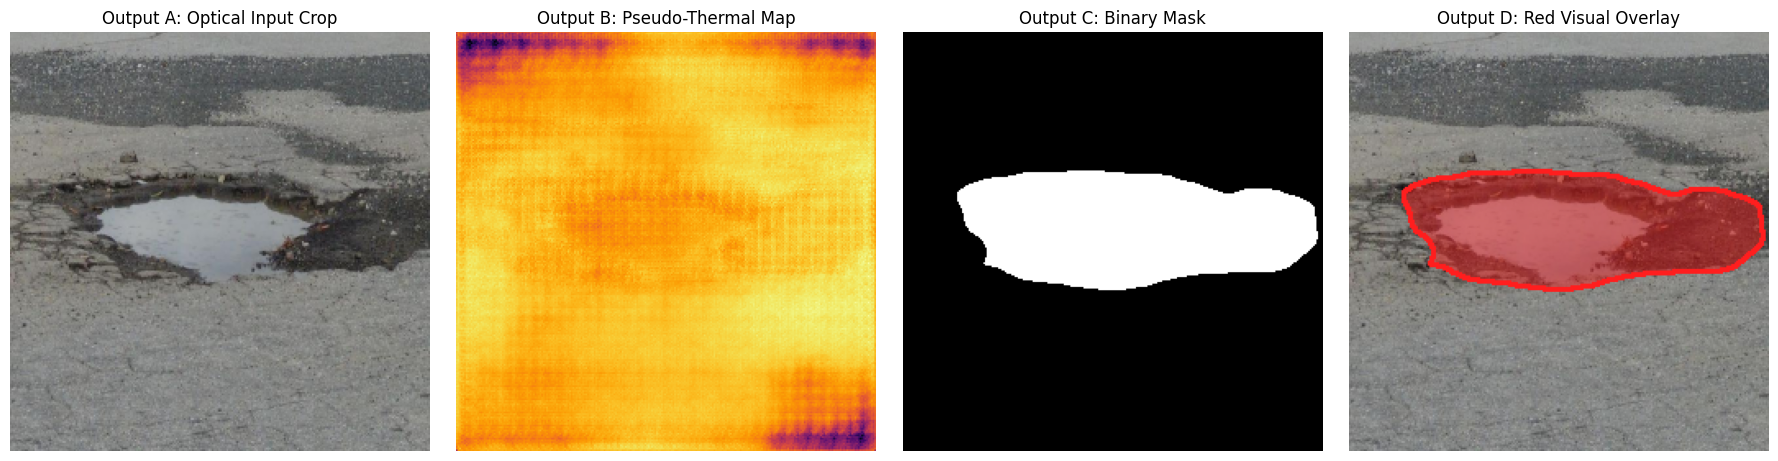

In [15]:
# Run inference on a sample pothole from the evaluation set
eval_set = test_dataset if len(test_dataset) > 0 else val_dataset
rgb_t, mask_t = eval_set[0]
rgb_batch = rgb_t.unsqueeze(0).to(device)

with torch.no_grad():
    prob_map, alpha, pseudo_thm = segmenter(rgb_batch)

rgb_disp = (denorm(rgb_t).transpose(1, 2, 0) * 255).astype(np.uint8)
prob_np = prob_map.squeeze().cpu().numpy()
mask_gt = mask_t.squeeze().cpu().numpy()
bin_pred = (prob_np >= 0.5).astype(np.uint8)

# 1-pixel outer rim contour
contours, _ = cv2.findContours(bin_pred * 255, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
rim_contour = np.zeros_like(bin_pred, dtype=np.uint8)
cv2.drawContours(rim_contour, contours, -1, 255, thickness=1)

# Red overlay preview
overlay = rgb_disp.copy()
m_bool = bin_pred > 0
overlay[m_bool] = (0.55 * rgb_disp[m_bool] + 0.45 * np.array([255, 30, 30])).astype(np.uint8)
cv2.drawContours(overlay, contours, -1, (255, 30, 30), thickness=2)

# Plot the 4-part Output Suite
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
axes[0].imshow(rgb_disp)
axes[0].set_title("Output A: Optical Input Crop")
axes[0].axis("off")

# Safely extract pseudo-thermal array from the denorm helper
thm_disp = denorm(pseudo_thm.squeeze())
axes[1].imshow(thm_disp, cmap="inferno")
axes[1].set_title("Output B: Pseudo-Thermal Map")
axes[1].axis("off")

axes[2].imshow(bin_pred * 255, cmap="gray")
axes[2].set_title("Output C: Binary Mask")
axes[2].axis("off")

axes[3].imshow(overlay)
axes[3].set_title("Output D: Red Visual Overlay")
axes[3].axis("off")

plt.tight_layout()
plt.show()